# 01 - Cycling networks and graph metrics

Computes the graph metrics $s_\mathcal{G}, c_\mathcal{G}, l_\mathcal{G}$ of the 14 cities (Section II-C, Table II of the paper), the size, length and budget $B_{\max}$ of each network (Table VI) and draws the Grenoble network coloured by CSCS (Fig. 3).

The 14 networks (`data/networks/*.csv`) come from an OpenStreetMap extraction (2024) with the DoS classification of the ITSC-2024 paper, simplified. Re-extracting them from today's OSM would give different networks, so they are frozen here.

Closeness centrality takes a few minutes on the big cities (Paris), so the results are cached in `results/metrics_cities.csv`; set `RECOMPUTE = True` to recompute.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # the cycling_tits package

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from cycling_tits import CITIES, FIGURES, RESULTS, load_network, load_survey, pretty, Model, alphas
FIGURES.mkdir(exist_ok=True)

In [2]:
from cycling_tits.metrics import strength, closeness, largest_connected_component
from cycling_tits.model import max_budget
from tqdm.auto import tqdm

RECOMPUTE = False
cache = RESULTS / "metrics_cities.csv"
if cache.exists() and not RECOMPUTE:
    metrics = pd.read_csv(cache, index_col="city")
else:
    rows = []
    for city in tqdm(CITIES):
        G = load_network(city)
        rows.append(dict(city=city, V=G.number_of_nodes(), E=G.number_of_edges(),
                         length_m=sum(d["distance"] for *_, d in G.edges(data=True)),
                         B_max_eur=max_budget(G, "cerema"),
                         s_G=strength(G, "cscs"), c_G=closeness(G, "cscs"),
                         l_G=largest_connected_component(G, "cscs")))
    metrics = pd.DataFrame(rows).set_index("city")
    RESULTS.mkdir(exist_ok=True)
    metrics.to_csv(cache)
metrics

C:\Users\Administrator\anaconda3\envs\cycling-tits\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  0%|          | 0/14 [00:00<?, ?it/s]

  7%|▋         | 1/14 [00:12<02:39, 12.27s/it]

 14%|█▍        | 2/14 [00:14<01:13,  6.15s/it]

 21%|██▏       | 3/14 [00:23<01:23,  7.59s/it]

 29%|██▊       | 4/14 [00:24<00:48,  4.84s/it]

... (8 outputs left out)

 93%|█████████▎| 13/14 [09:27<01:14, 74.85s/it] 

100%|██████████| 14/14 [09:46<00:00, 57.80s/it]

100%|██████████| 14/14 [09:46<00:00, 41.88s/it]

,V,E,length_m,B_max_eur,s_G,c_G,l_G
city,,,,,,,
Angers,4118,4986,5.468543e+05,3.072305e+08,0.441987,0.357481,0.111289
Annecy,2286,2628,3.011331e+05,1.704615e+08,0.346921,0.288683,0.054335
Bordeaux,3757,4816,5.474337e+05,2.915603e+08,0.423265,0.387958,0.065257
Chambery,1184,1244,1.284919e+05,6.412534e+07,0.393947,0.329095,0.172866
Dunkerque,2465,3117,3.764465e+05,1.964351e+08,0.456512,0.504900,0.086952
Grenoble,3539,5065,4.152133e+05,2.366527e+08,0.416956,0.426304,0.202789
La_Rochelle,4168,5425,4.891858e+05,2.788343e+08,0.355654,0.427456,0.152919
Le_Havre,1363,1488,3.719671e+05,1.768448e+08,0.550382,0.496296,0.120851
Lyon,6200,9005,9.237834e+05,5.864217e+08,0.345344,0.407790,0.166468


## Table II - metrics and perceived safety / comfort (Baromètre Vélo, scaled to [0, 1])

In [3]:
survey = load_survey()
table2 = metrics[["s_G", "c_G", "l_G"]].round(4).join(survey[["y_safety", "y_comfort"]])
table2.index = [pretty(c) for c in table2.index]
table2

,s_G,c_G,l_G,y_safety,y_comfort
Angers,0.4420,0.3575,0.1113,0.420,0.484
Annecy,0.3469,0.2887,0.0543,0.448,0.552
Bordeaux,0.4233,0.3880,0.0653,0.440,0.458
Chambery,0.3939,0.3291,0.1729,0.514,0.564
Dunkerque,0.4565,0.5049,0.0870,0.488,0.524
Grenoble,0.4170,0.4263,0.2028,0.608,0.674
La Rochelle,0.3557,0.4275,0.1529,0.566,0.608
Le Havre,0.5504,0.4963,0.1209,0.458,0.444
Lyon,0.3453,0.4078,0.1665,0.440,0.508
Nantes,0.3507,0.3445,0.0557,0.470,0.522


## Table VI - networks and budget $B_{\max}$ (Cerema costs, EUR)

In [5]:
table6 = metrics[["V", "E", "length_m", "B_max_eur"]].copy()
table6["length_m"] = table6["length_m"].round(0).astype(int)
table6["B_max_eur"] = table6["B_max_eur"].astype(int).map("{:,}".format)
table6.index = [pretty(c) for c in table6.index]
table6

,V,E,length_m,B_max_eur
Angers,4118,4986,546854,"307,230,491"
Annecy,2286,2628,301133,"170,461,482"
Bordeaux,3757,4816,547434,"291,560,346"
Chambery,1184,1244,128492,"64,125,336"
Dunkerque,2465,3117,376446,"196,435,124"
Grenoble,3539,5065,415213,"236,652,715"
La Rochelle,4168,5425,489186,"278,834,295"
Le Havre,1363,1488,371967,"176,844,796"
Lyon,6200,9005,923783,"586,421,676"
Nantes,8984,11504,1106162,"682,956,132"


## Fig. 3 - Grenoble cycling network coloured by CSCS

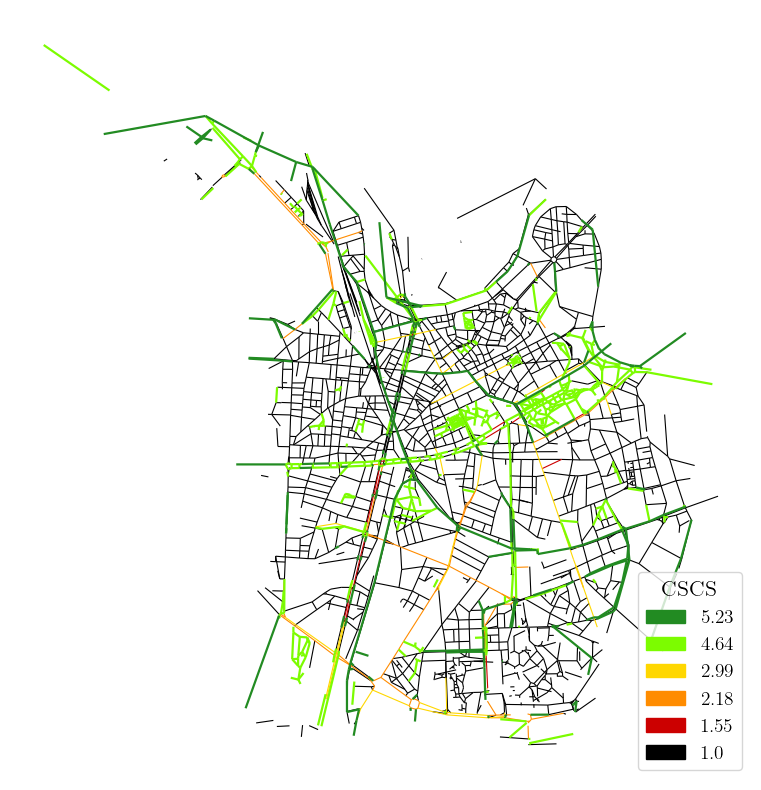

In [6]:
from cycling_tits.plotting import city_map
G = load_network("Grenoble")
city_map(G, outfile=FIGURES / "Map_and_scale.png");

## Sioux Falls test network (Fig. 8)
DoS values were drawn at random once (2024) and are frozen in `data/networks/Sioux_Falls_*.csv`.

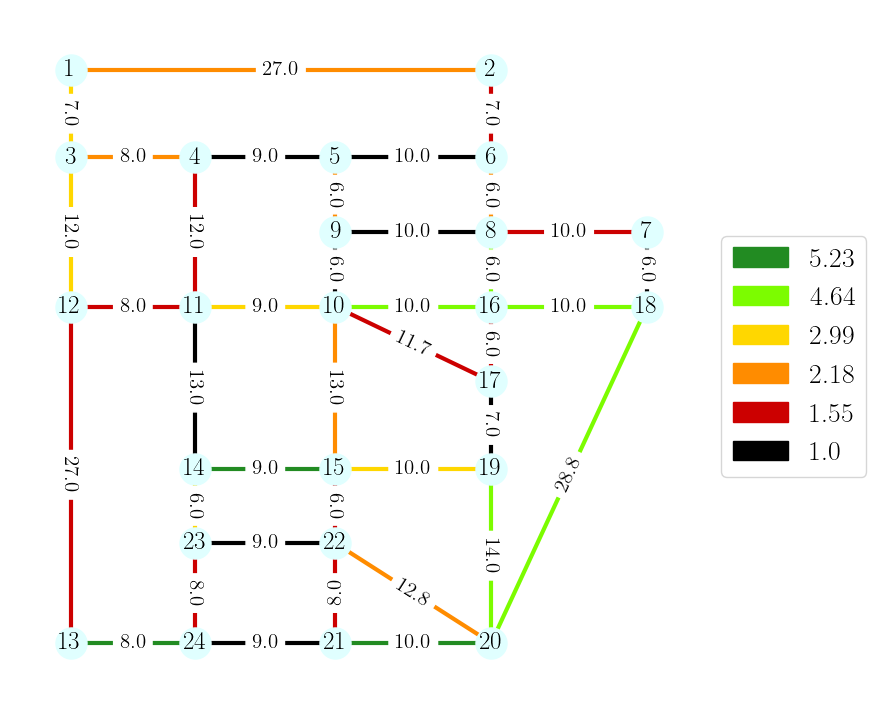

In [7]:
from cycling_tits.plotting import sioux_falls_network
sioux_falls_network(load_network("Sioux_Falls"), outfile=FIGURES / "Sioux_Falls.png");